In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from dataclasses import dataclass
from pathlib import Path
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
)

df = pd.read_csv("battery_observations.csv", index_col=0)
meta = pd.read_csv("battery_metadata.csv", index_col=0)
df2 = df.join(meta[["climate_zone", "chemistry"]])
df2 = df2.sort_values(["battery_id", "cycle_index"])
df2 = df2.reset_index()
meta = meta.reset_index()
g = lambda x: int(x.split('-')[-1])
df2["battery_id"] = df2["battery_id"].apply(g)
meta["battery_id"] = meta["battery_id"].apply(g)
battery_ids = list(set(df2["battery_id"]))
materials = list(set(meta["chemistry"]))
climate_zones = list(set(meta["climate_zone"]))
labels = list(set(df2["degradation_status"]))

train_labels = pd.read_csv("train_batteries.csv")["battery_id"].apply(g)
val_labels = pd.read_csv("validation_batteries.csv")["battery_id"].apply(g)

train = df2[df2["battery_id"].isin(train_labels)]
val = df2[df2["battery_id"].isin(val_labels)]

I0000 00:00:1794988352.453239    6595 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794988352.757444    6595 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794988354.342205    6595 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
features_A = [
    "battery_age_days",
    "equivalent_full_cycles",
    "internal_resistance_mOhm",
    "cumulative_high_temp_hours",
]
features_B = features_A + ["cycle_index"]
features_C = features_B + ["ambient_temp_c"]
features = [features_A, features_B, features_C] # all feature sets together
label_names = ["A", "B", "C"]

In [3]:
use_features = features_C

# Simple unsupervised deep-learning baseline for battery charge-discharge cycles.
#
# Input: one row = one battery cycle.
# Output:
#   - Reconstruction error per cycle (anomaly/degradation score)
#   - 8-dimensional latent embedding for clustering / visualization
#
# The model does not use degradation_status during training.


def make_feature_matrix(dataframe, feature_columns):
    """
    Extracts the numeric feature matrix used by the autoencoder.

    Returns
    -------
    X : np.ndarray, shape (n_cycles, n_features)
    feature_names : list[str]
    """
    missing = [c for c in feature_columns if c not in dataframe.columns]
    if missing:
        raise ValueError(f"Missing expected feature columns: {missing}")

    X = dataframe[feature_columns].copy()

    # Simple missing-value handling. Median imputation is robust for a baseline.
    X = X.fillna(X.median(numeric_only=True))

    # Convert booleans such as cooling_active to numeric values.
    X = X.astype(np.float32)

    return X.to_numpy(), feature_columns


X_train_raw, feature_names = make_feature_matrix(train, use_features)
X_val_raw, _ = make_feature_matrix(val, feature_names)




In [4]:

# ---------------------------------------------------------------------------
# Model
# ---------------------------------------------------------------------------

def build_autoencoder(
    n_features,
    hidden_dim,
    latent_dim,
    dropout,
    learning_rate,
):
    """
    Plain fully connected autoencoder.

    Training model output:
        reconstruction only

    Latent embedding:
        extracted separately after training
    """
    inputs = keras.Input(shape=(n_features,), name="cycle_features")

    # Encoder
    x = layers.Dense(hidden_dim, activation="relu", name="encoder_dense_1")(inputs)
    x = layers.Dropout(dropout, name="encoder_dropout")(x)
    latent = layers.Dense(latent_dim, activation="linear", name="latent_embedding")(x)

    # Decoder
    x = layers.Dense(hidden_dim, activation="relu", name="decoder_dense_1")(latent)
    reconstruction = layers.Dense(n_features, activation="linear", name="reconstruction")(x)

    # Training model: only reconstruction is returned.
    autoencoder = keras.Model(
        inputs=inputs,
        outputs=reconstruction,
        name="battery_cycle_autoencoder",
    )

    autoencoder.compile(
        optimizer=keras.optimizers.Adam(learning_rate),
        loss="mse",
    )

    # Separate model for extracting the latent embedding after training.
    encoder = keras.Model(
        inputs=inputs,
        outputs=latent,
        name="battery_cycle_encoder",
    )

    return autoencoder, encoder


In [5]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)

def train_autoencoder(model, encoder,
                      X_train, X_val, y_train, y_val,
                      latent_dim, hidden_dim, dropout_rate, learning_rate):

    # --------------------------------------------------
    # 1. Train the autoencoder
    # --------------------------------------------------

    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=PATIENCE,
            restore_best_weights=True,
            verbose=1,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=max(1, PATIENCE // 2),
            min_lr=1e-5,
            verbose=1,
        ),
    ]

    history = model.fit(
        x=X_train,
        y=X_train,
        validation_data=(X_val, X_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=True,
        callbacks=callbacks,
        verbose=1,
    )

    # Evaluate reconstruction performance after training
    val_mse = model.evaluate(X_val, X_val, verbose=0)

    # --------------------------------------------------
    # 2. Extract latent representations using the encoder
    # --------------------------------------------------

    train_latent = encoder.predict(X_train, verbose=0)
    val_latent = encoder.predict(X_val, verbose=0)

    # --------------------------------------------------
    # 3. Train KNN using latent representations
    # --------------------------------------------------

    knn = KNeighborsClassifier(n_neighbors=4)

    knn.fit(train_latent, y_train)

    val_pred = knn.predict(val_latent)

    # --------------------------------------------------
    # 4. Calculate evaluation metrics
    # --------------------------------------------------

    metrics = {
        "latent_dim": latent_dim,
        "hidden_dim": hidden_dim,
        "dropout_rate": dropout_rate,
        "learning_rate": learning_rate,
        "val_mse": val_mse,
        "ARI": adjusted_rand_score(y_val, val_pred),
        "NMI": normalized_mutual_info_score(y_val, val_pred),
        "accuracy": accuracy_score(y_val, val_pred),
        "macro_F1": f1_score(
            y_val, val_pred,
            average="macro",
            zero_division=0
        ),
        "val_pred": val_pred,
        "train_latent": train_latent,
        "val_latent": val_latent,
    }
    metrics["val_error"] = 1 - metrics["accuracy"]

    return metrics


Epoch 1/20


E0000 00:00:1794988358.048180    6595 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1794988358.077926    6595 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


6113/6113 ━━━━━━━━━━━━━━━━━━━━ 7s 990us/step - loss: 0.0032 - val_loss: 3.2355e-04 - learning_rate: 0.0100
Epoch 2/20
6113/6113 ━━━━━━━━━━━━━━━━━━━━ 6s 1ms/step - loss: 6.9330e-04 - val_loss: 3.1977e-04 - learning_rate: 0.0100
Epoch 3/20
6113/6113 ━━━━━━━━━━━━━━━━━━━━ 6s 971us/step - loss: 6.4476e-04 - val_loss: 2.4194e-04 - learning_rate: 0.0100
Epoch 4/20
6113/6113 ━━━━━━━━━━━━━━━━━━━━ 6s 969us/step - loss: 5.5764e-04 - val_loss: 1.2220e-04 - learning_rate: 0.0100
Epoch 5/20
6113/6113 ━━━━━━━━━━━━━━━━━━━━ 6s 974us/step - loss: 5.2535e-04 - val_loss: 1.0648e-04 - learning_rate: 0.0100
Epoch 6/20
6113/6113 ━━━━━━━━━━━━━━━━━━━━ 6s 966us/step - loss: 4.2451e-04 - val_loss: 4.6622e-04 - learning_rate: 0.0100
Epoch 7/20
6113/6113 ━━━━━━━━━━━━━━━━━━━━ 6s 974us/step - loss: 4.4315e-04 - val_loss: 2.6468e-04 - learning_rate: 0.0100
Epoch 8/20
6113/6113 ━━━━━━━━━━━━━━━━━━━━ 6s 978us/step - loss: 4.1954e-04 - val_loss: 3.2773e-05 - learning_rate: 0.0100
Epoch 9/20
6056/6113 ━━━━━━━━━━━━━━━━━━━━

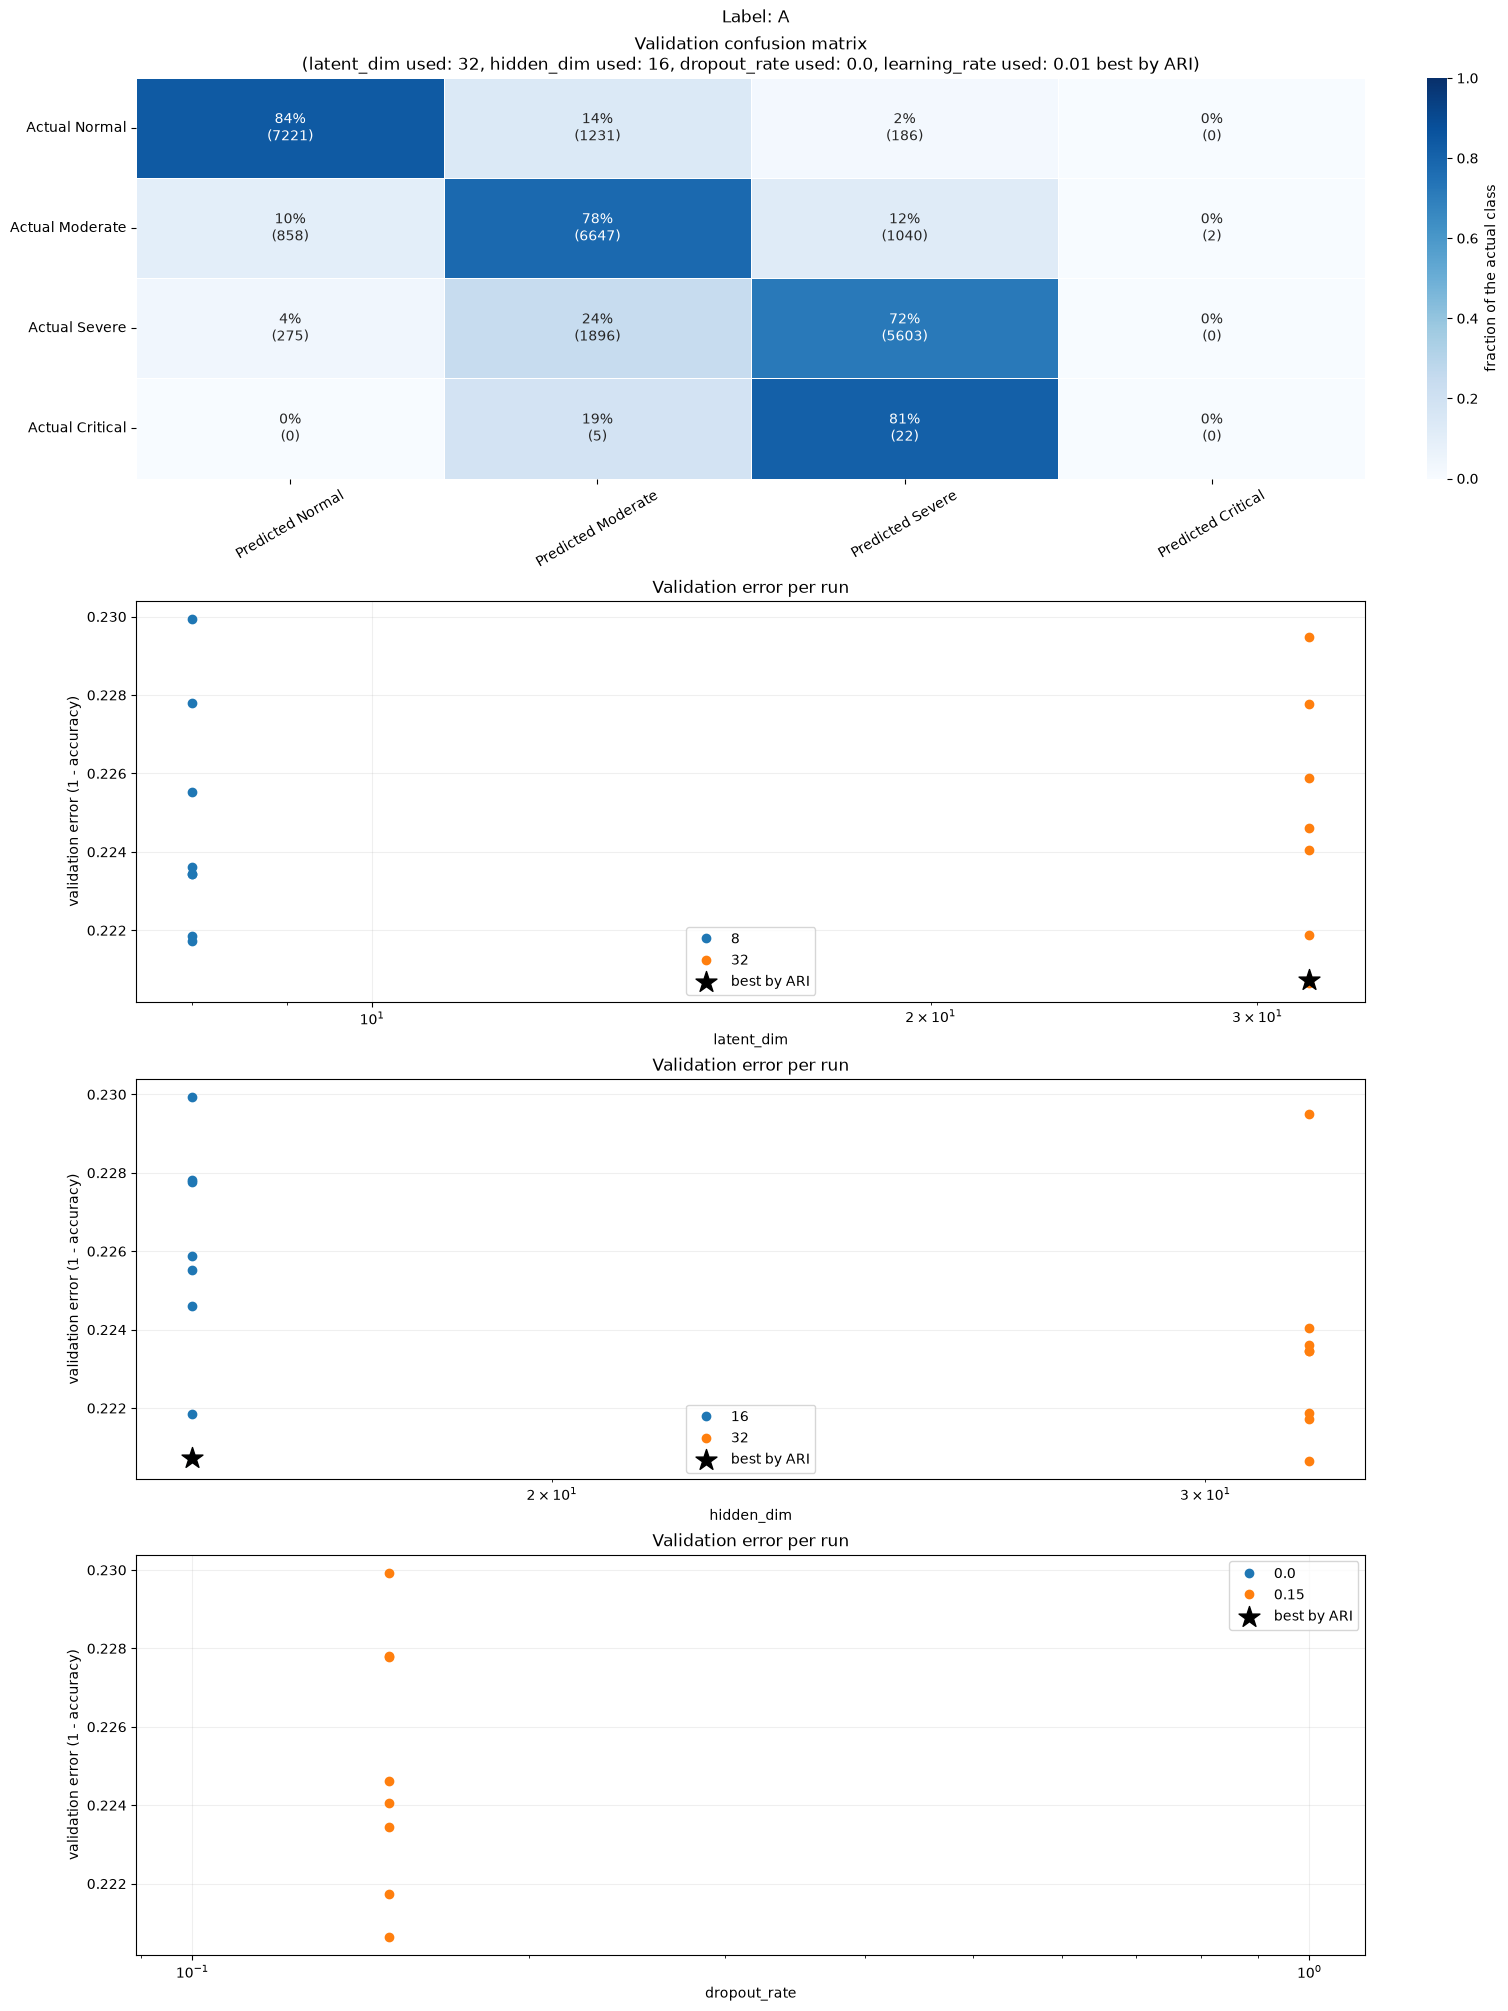

--label-- A metric df:
    latent_dim  hidden_dim  dropout_rate  learning_rate       val_mse  \
8           32          16          0.00        0.01000  4.827053e-06   
15          32          32          0.15        0.00001  7.916003e-03   
12          32          32          0.00        0.01000  4.931667e-07   
0            8          16          0.00        0.01000  6.110211e-07   
6            8          32          0.15        0.01000  1.346839e-02   
5            8          32          0.00        0.00001  2.589050e-04   
4            8          32          0.00        0.01000  4.970001e-06   
14          32          32          0.15        0.01000  1.848375e-02   
7            8          32          0.15        0.00001  6.120396e-03   
10          32          16          0.15        0.01000  3.515701e-02   
9           32          16          0.00        0.00001  5.380675e-04   
1            8          16          0.00        0.00001  1.384750e-03   
2            8          16  

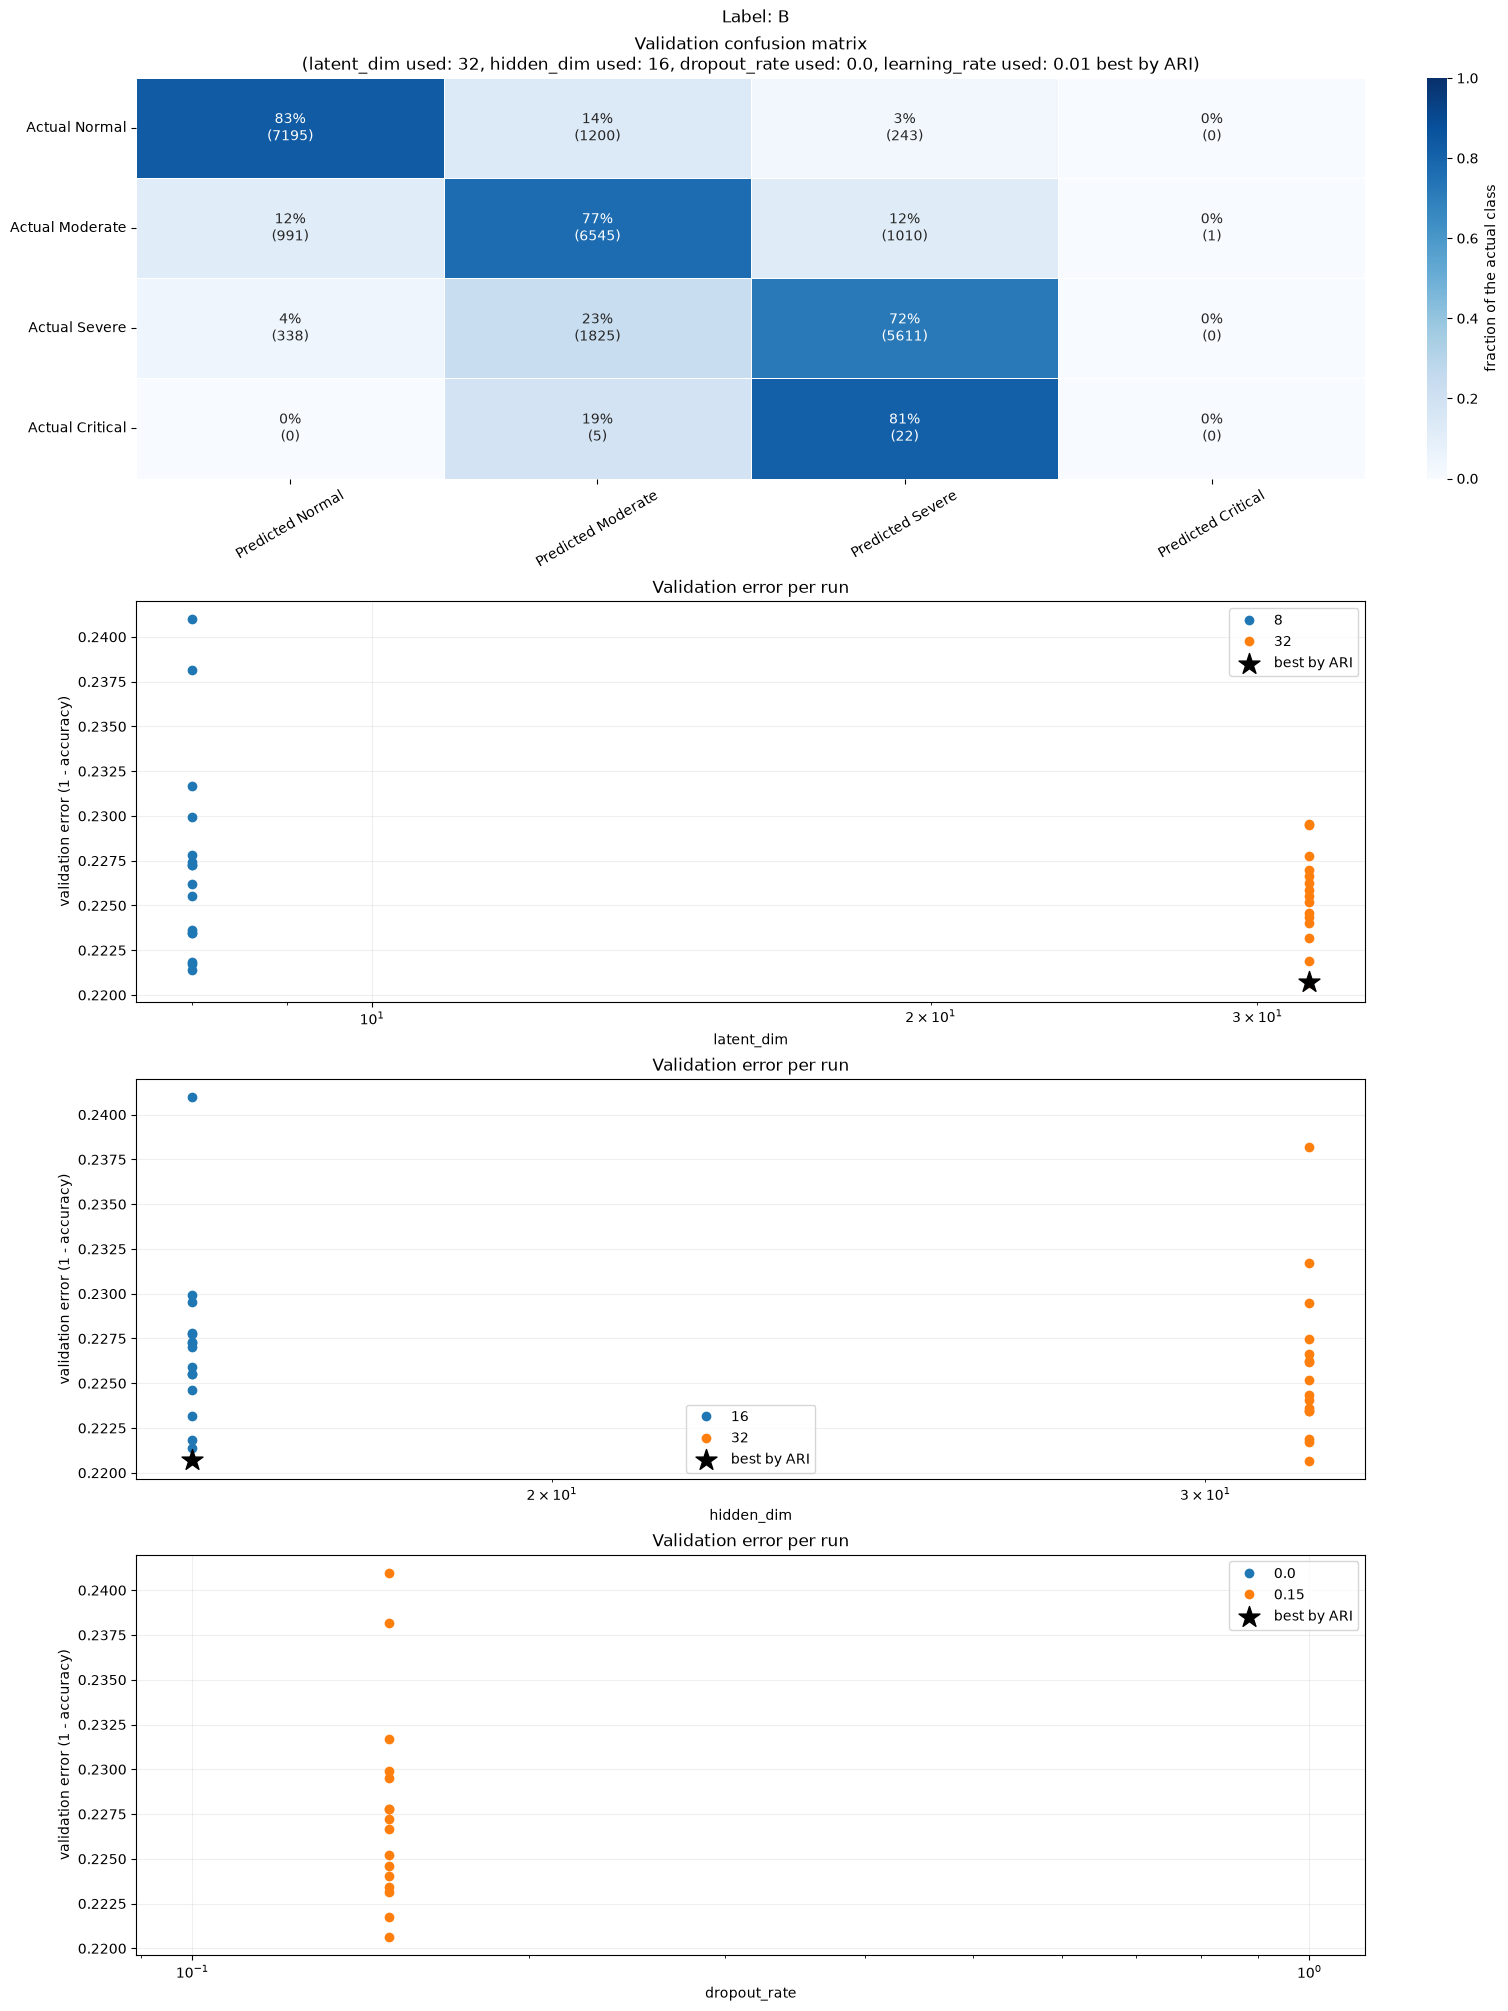

--label-- B metric df:
    latent_dim  hidden_dim  dropout_rate  learning_rate       val_mse  \
8           32          16          0.00        0.01000  4.827053e-06   
17           8          16          0.00        0.00001  6.091478e-03   
15          32          32          0.15        0.00001  7.916003e-03   
12          32          32          0.00        0.01000  4.931667e-07   
0            8          16          0.00        0.01000  6.110211e-07   
26          32          16          0.15        0.01000  5.637841e-02   
6            8          32          0.15        0.01000  1.346839e-02   
5            8          32          0.00        0.00001  2.589050e-04   
4            8          32          0.00        0.01000  4.970001e-06   
14          32          32          0.15        0.01000  1.848375e-02   
30          32          32          0.15        0.01000  2.219374e-02   
7            8          32          0.15        0.00001  6.120396e-03   
10          32          16  

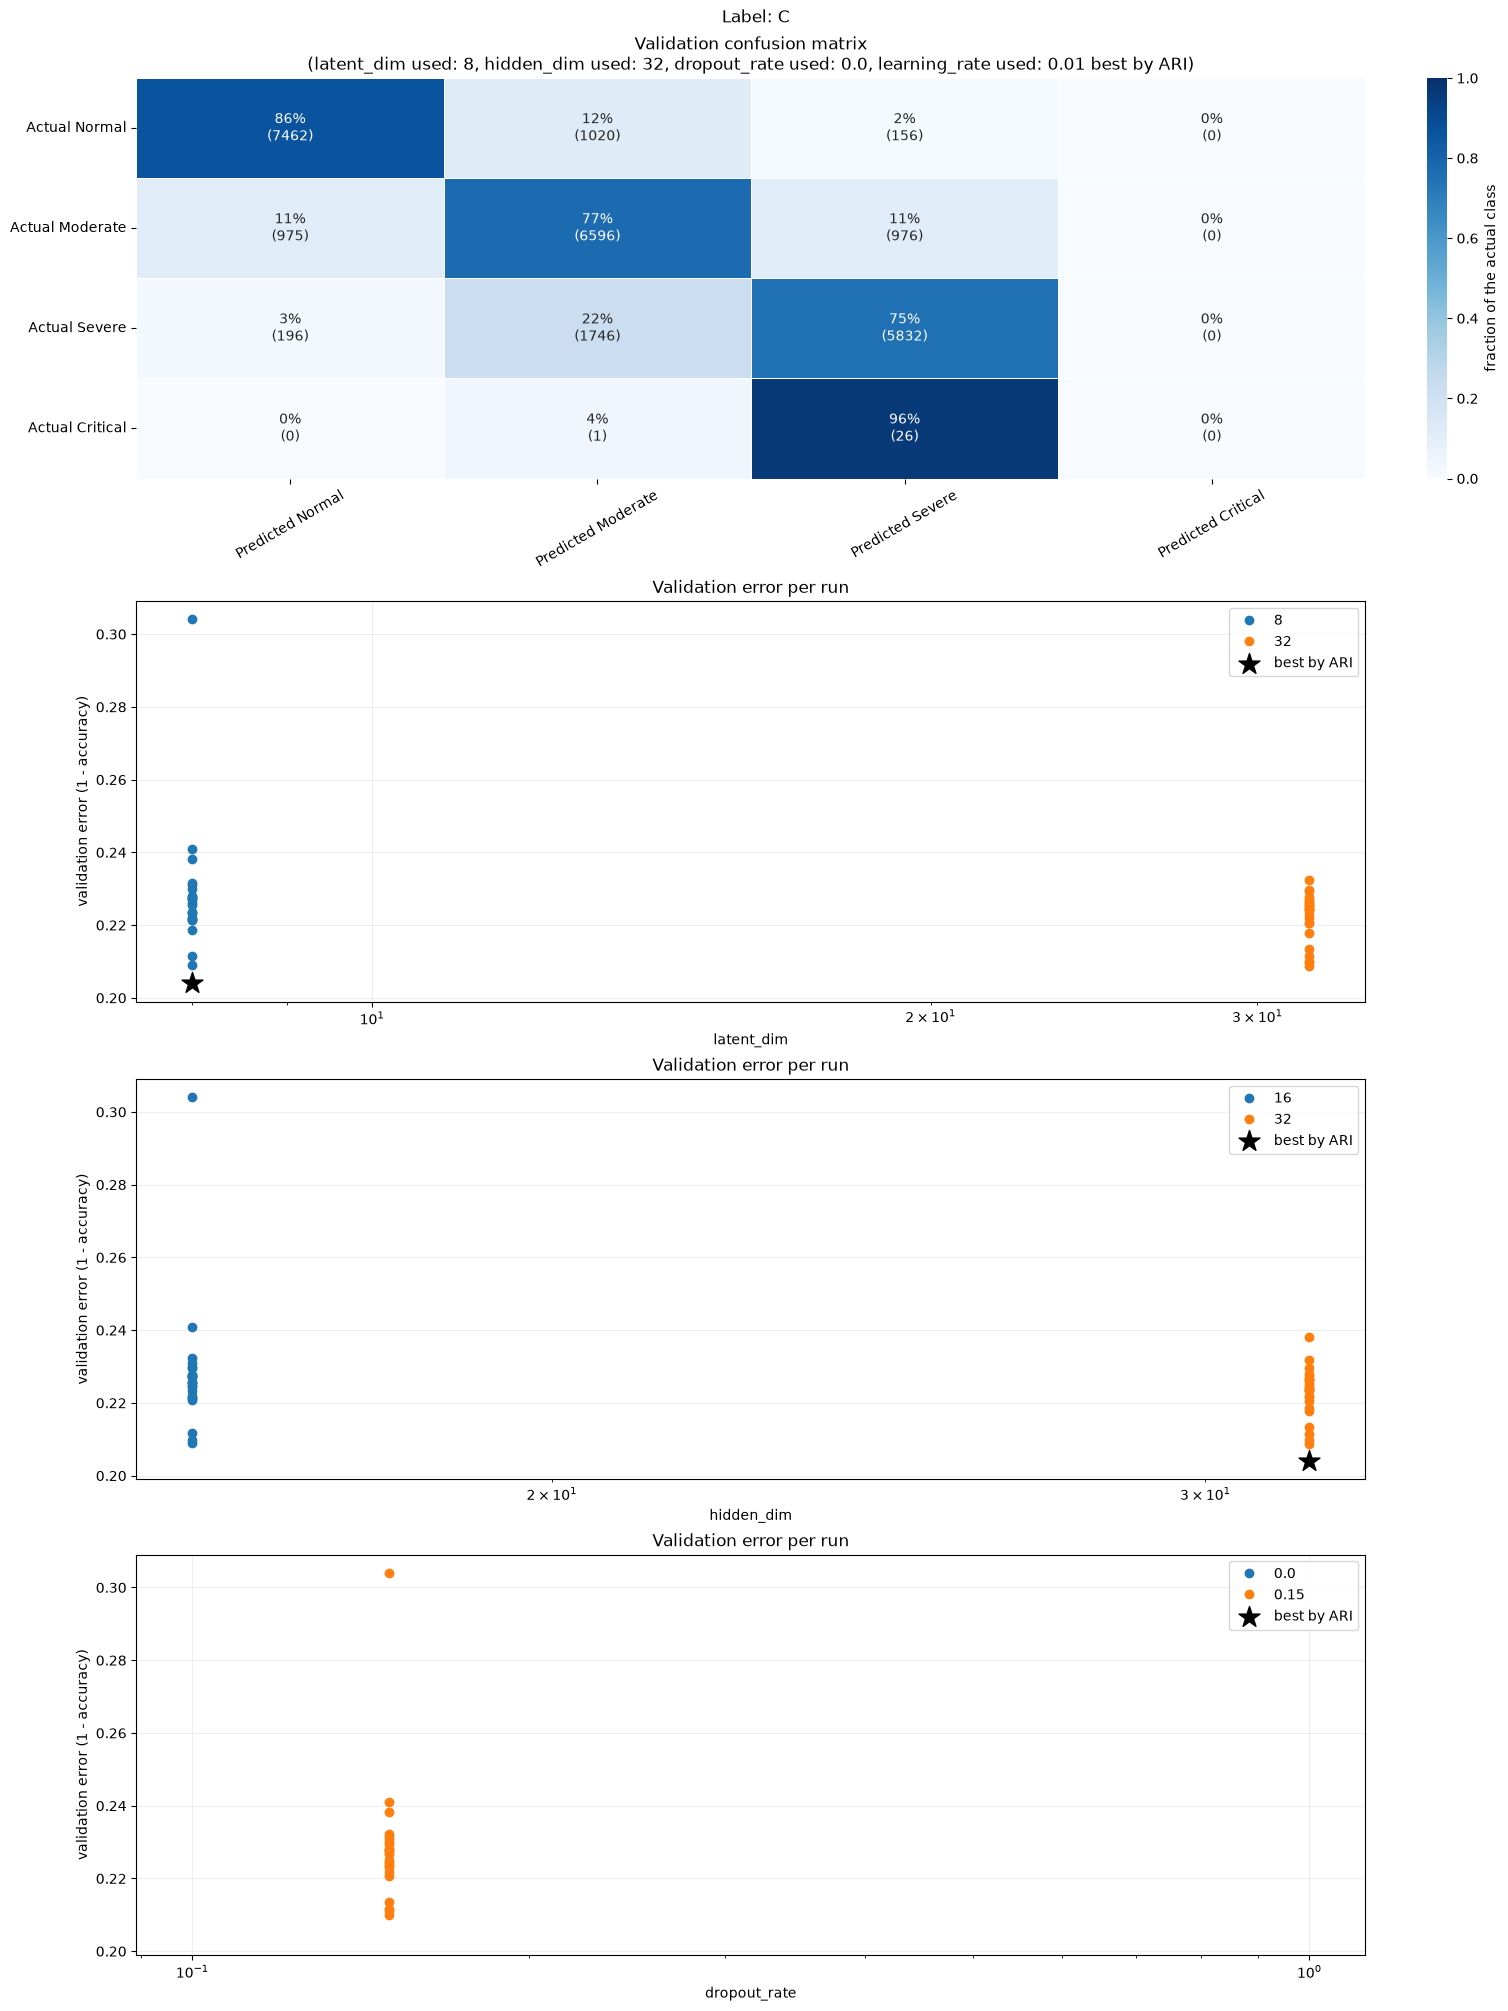

--label-- C metric df:
    latent_dim  hidden_dim  dropout_rate  learning_rate       val_mse  \
36           8          32          0.00        0.01000  2.188832e-05   
32           8          16          0.00        0.01000  2.815948e-06   
44          32          32          0.00        0.01000  4.450610e-05   
40          32          16          0.00        0.01000  1.442092e-06   
47          32          32          0.15        0.00001  1.129163e-02   
42          32          16          0.15        0.01000  8.841605e-02   
38           8          32          0.15        0.01000  1.304944e-02   
46          32          32          0.15        0.01000  2.807576e-02   
45          32          32          0.00        0.00001  2.958668e-04   
37           8          32          0.00        0.00001  3.495315e-03   
8           32          16          0.00        0.01000  4.827053e-06   
17           8          16          0.00        0.00001  6.091478e-03   
15          32          32  

In [ ]:
from itertools import product
import seaborn as sns

LATENT_DIMS = [8, 32]
HIDDEN_DIMS = [16, 32]
DROPOUT_RATES = [0.0, 0.15]
LEARNING_RATES = [1e-2, 1e-5]

class_names = ["Normal", "Moderate", "Severe", "Critical"]

optimize_metric = "ARI" # out of ARI, silhouette, NMI, accuracy, macro_F1

EPOCHS = 100
PATIENCE = 10
MODEL_PATH = "model.keras"
BATCH_SIZE = 5

OPTIMIZE_METRIC = "ARI"  # ARI, NMI, accuracy, macro_F1
HIGHER_IS_BETTER = True

EPOCHS = 20
PATIENCE = 10
MODEL_PATH = "model.keras"
BATCH_SIZE = 20

latent_dim_mapping = {LATENT_DIMS[x]:x for x in range(len(LATENT_DIMS))}
hidden_dim_mapping = {HIDDEN_DIMS[x]:x for x in range(len(HIDDEN_DIMS))}
dropout_rate_mapping = {DROPOUT_RATES[x]:x for x in range(len(DROPOUT_RATES))}
learning_rate_mapping = {LEARNING_RATES[x]:x for x in range(len(LEARNING_RATES))}

l1,l2,l3,l4 = len(LATENT_DIMS),len(HIDDEN_DIMS),len(DROPOUT_RATES),len(LEARNING_RATES)

metrics_all = []

def run_for_features(use_features, label):

    preprocess = Pipeline([
        ("scaler", StandardScaler()),
        ("variance", VarianceThreshold(threshold=0.0))
    ])

    X_train = preprocess.fit_transform(train[use_features])
    X_val = preprocess.transform(val[use_features])
    y_train = train["degradation_status"].to_numpy()
    y_val = val["degradation_status"].to_numpy()

    encoder_struct = np.empty((l1,l2,l3,l4), dtype=object)
    autoencoder_struct = np.empty_like(encoder_struct, dtype=object)
    val_pred_struct = np.empty_like(encoder_struct, dtype=object)

    for i, j, k, l in product(
        range(len(LATENT_DIMS)),
        range(len(HIDDEN_DIMS)),
        range(len(DROPOUT_RATES)),
        range(len(LEARNING_RATES)),
    ):
        latent_dim = LATENT_DIMS[i]
        hidden_dim = HIDDEN_DIMS[j]
        dropout_rate = DROPOUT_RATES[k]
        learning_rate = LEARNING_RATES[l]

        autoencoder, encoder = build_autoencoder(X_train.shape[1], hidden_dim, latent_dim, dropout_rate, learning_rate)
        metrics = train_autoencoder(autoencoder, encoder, X_train, X_val, y_train, y_val, latent_dim, hidden_dim, dropout_rate, learning_rate)
        metrics_all.append(metrics)
        encoder_struct[i,j,k,l] = encoder
        autoencoder_struct[i,j,k,l] = autoencoder
        val_pred_struct[i,j,k,l] = metrics["val_pred"]
        
    metrics_df = pd.DataFrame(metrics_all).sort_values(optimize_metric, ascending=False)
    best = metrics_df.iloc[0]
    
    # best_autoencoder = autoencoder_struct[
    #     latent_dim_mapping[metrics_df["latent_dim"].values[0]],
    #     hidden_dim_mapping[metrics_df["hidden_dim"].values[0]],
    #     dropout_rate_mapping[metrics_df["dropout_rate"].values[0]],
    #     learning_rate_mapping[metrics_df["learning_rate"].values[0]],
    #     ]
    # best_encoder = encoder_struct[
    #     latent_dim_mapping[metrics_df["latent_dim"].values[0]],
    #     hidden_dim_mapping[metrics_df["hidden_dim"].values[0]],
    #     dropout_rate_mapping[metrics_df["dropout_rate"].values[0]],
    #     learning_rate_mapping[metrics_df["learning_rate"].values[0]],
    #     ]

    best_pred = val_pred_struct[
        latent_dim_mapping[metrics_df["latent_dim"].values[0]],
        hidden_dim_mapping[metrics_df["hidden_dim"].values[0]],
        dropout_rate_mapping[metrics_df["dropout_rate"].values[0]],
        learning_rate_mapping[metrics_df["learning_rate"].values[0]],
        ]

    cm = confusion_matrix(y_val, best_pred, labels=class_names)
    cm_frac = cm / np.clip(cm.sum(axis=1, keepdims=True), 1, None)   # correct / total per actual class
    annot = np.array([[f"{cm_frac[i, j]:.0%}\n({cm[i, j]})" for j in range(cm.shape[1])]
                        for i in range(cm.shape[0])])

    fig, (ax_cm, ax_err_latent, ax_err_hidden, ax_err_dropout) = plt.subplots(4, 1, figsize=(15, 20), layout="constrained")

    sns.heatmap(cm_frac, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1,
                xticklabels=[f"Predicted {c}" for c in class_names],
                yticklabels=[f"Actual {c}" for c in class_names],
                linewidths=0.5, linecolor="white",
                cbar_kws={"label": "fraction of the actual class"}, ax=ax_cm)
    ax_cm.set_title(f"Validation confusion matrix\n"
                    f"(latent_dim used: {best['latent_dim']}, hidden_dim used: {best['hidden_dim']}, dropout_rate used: {best['dropout_rate']}, learning_rate used: {best['learning_rate']} best by {optimize_metric})")
    ax_cm.tick_params(axis="x", rotation=30)
    ax_cm.tick_params(axis="y", rotation=0)

    # validation error of every run
    for latdim, g in metrics_df.groupby("latent_dim"):
        ax_err_latent.plot(g["latent_dim"], g["val_error"], marker="o", label=latdim, linestyle="none")
    ax_err_latent.scatter([best["latent_dim"]], [best["val_error"]], marker="*", s=250,
                    color="black", zorder=5, label=f"best by {optimize_metric}")
    for hitdim, g in metrics_df.groupby("hidden_dim"):
        ax_err_hidden.plot(g["hidden_dim"], g["val_error"], marker="o", label=hitdim, linestyle="none")
    ax_err_hidden.scatter([best["hidden_dim"]], [best["val_error"]], marker="*", s=250,
                    color="black", zorder=5, label=f"best by {optimize_metric}")
    for dropout, g in metrics_df.groupby("dropout_rate"):
        ax_err_dropout.plot(g["dropout_rate"], g["val_error"], marker="o", label=dropout, linestyle="none")
    ax_err_dropout.scatter([best["dropout_rate"]], [best["val_error"]], marker="*", s=250,
                    color="black", zorder=5, label=f"best by {optimize_metric}")
    
    ax_err_latent.set_xscale("log")
    ax_err_hidden.set_xscale("log")
    ax_err_dropout.set_xscale("log")

    ax_err_latent.set_xlabel("latent_dim")
    ax_err_hidden.set_xlabel("hidden_dim")
    ax_err_dropout.set_xlabel("dropout_rate")

    ax_err_latent.set_ylabel("validation error (1 - accuracy)")
    ax_err_hidden.set_ylabel("validation error (1 - accuracy)")
    ax_err_dropout.set_ylabel("validation error (1 - accuracy)")

    ax_err_latent.set_title("Validation error per run")
    ax_err_hidden.set_title("Validation error per run")
    ax_err_dropout.set_title("Validation error per run")

    ax_err_latent.grid(alpha=0.2)
    ax_err_hidden.grid(alpha=0.2)
    ax_err_dropout.grid(alpha=0.2)

    ax_err_latent.legend()
    ax_err_hidden.legend()
    ax_err_dropout.legend()

    fig.suptitle(f"Label: {label}", fontsize=12)
    plt.savefig(Path.cwd() / "images" / "autoencoder" / f"set_{label}.png")
    plt.show()

    return metrics_df


all_metrics = {}
for label, feature in zip(label_names, features):
    metrics_df = run_for_features(feature, label)
    metrics_df.to_pickle(
        Path.cwd() / "saves" / "unsupervised_DL" / f"label_{label}.pkl"
    )
    print('--label--', label, 'metric df:'); print(metrics_df); print()